## Cap 6 - Balanceamento de forças e momentos de inércia de um motor alternativo

Motor de $n$ cilindros, 4 tempos, com uma dada **ordem de ignição**.

- Ângulo entre ignições consecutivas (dentro do ciclo de 720° de um motor 4 tempos):
$$\alpha_g = \frac{360 \times 2}{n}$$
- O cilindro que dispara na posição $k$ (0-based) da ordem de ignição tem manivela no ângulo
$$\theta_k = k\,\alpha_g \pmod{360°}$$
medido a partir do cilindro que dispara primeiro (0°, "para cima"), crescendo no sentido horário — mesma convenção usada nas Figuras 1 a 3 da resolução.
- O esforço de inércia de ordem (harmônico) $h$ — $h=1$: primário; $h=2$: secundário; $h=3$: terciário; e assim por diante — tem direção
$$\theta_{k,h} = h\,\theta_k = h\,k\,\alpha_g \pmod{360°}$$
pois a defasagem de um harmônico de ordem $h$ é $h$ vezes a defasagem entre manivelas consecutivas.
- Força de inércia do cilindro $j$, no harmônico $h$: módulo $F_j$ (igual para todos os cilindros, hipótese usual), na direção $\theta_{k,h}$ correspondente.
- Momento do cilindro $j$ nesse mesmo harmônico, tomado em relação ao centro do cilindro 1 (referência):
$$M_j = F_j\,(j-1)\,a$$
na mesma direção da força, onde $a$ é o espaçamento entre cilindros e $j$ é o **número físico** do cilindro (posição ao longo do eixo de manivelas), não a posição na ordem de ignição.

O motor está balanceado, para o harmônico em questão, se a soma vetorial (das forças ou dos momentos) for nula. A rotina abaixo (`angulo_harmonico` / `montar_esforcos`) aceita qualquer ordem de harmônico $h$ — não só 1 e 2 — bastando passar `harmonico=h`.

In [66]:
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict


def ordem_para_angulos(ordem_ignicao, tempos, alpha_g=None):
    """
    ordem_ignicao: lista com a ordem de ignição dos cilindros, ex: [1,5,3,4,2,6]
    alpha_g: ângulo entre ignições consecutivas (graus). Se None, calcula-se
             alpha_g = 360*(tempos/2)/n_cilindros (motor 4 tempos).

    Retorna alpha_g e uma lista de dicionários (um por cilindro, ordenada pelo
    número físico do cilindro) com:
      'cilindro' -> número físico do cilindro (usado no braço do momento)
      'posicao'  -> posição (0-based) na ordem de ignição

    Os ângulos de cada harmônico não ficam fixos aqui: são calculados sob
    demanda por `angulo_harmonico`, para qualquer ordem de harmônico (1º, 2º,
    3º, ...).
    """
    n = len(ordem_ignicao)
    if alpha_g is None:
        alpha_g = 360 * (tempos / 2) / n

    dados = [{'cilindro': cilindro, 'posicao': posicao}
             for posicao, cilindro in enumerate(ordem_ignicao)]
    dados.sort(key=lambda d: d['cilindro'])
    return alpha_g, dados


def angulo_harmonico(posicao, alpha_g, harmonico):
    """
    Ângulo de fase do harmônico de ordem `harmonico` (1 = esforços primários,
    2 = secundários, 3 = terciários, ... qualquer inteiro positivo) para o
    cilindro que dispara na posição `posicao` (0-based) da ordem de ignição:

        theta_h = harmonico * posicao * alpha_g  (mod 360°)

    (a defasagem de um harmônico de ordem h é h vezes a defasagem entre as
    manivelas consecutivas na ordem de ignição).
    """
    return (harmonico * posicao * alpha_g) % 360


def vetor(modulo, angulo_graus):
    """(módulo, ângulo) -> (x, y). Convenção: 0° para cima, ângulo cresce no sentido horário."""
    theta = np.radians(angulo_graus)
    return modulo * np.sin(theta), modulo * np.cos(theta)


def montar_esforcos(dados, alpha_g, F=1.0, a=1.0, harmonico=1):
    """
    Monta os vetores de força e de momento de inércia para o harmônico de
    ordem `harmonico` (1 = esforços primários, 2 = secundários, 3 =
    terciários, ... a construção é a mesma para qualquer ordem).

    F pode ser um escalar (mesma força em todos os cilindros) ou um dict
    {cilindro: F_j}. M_j = F_j*(j-1)*a, com j = número físico do cilindro.

    Retorna (forcas, momentos): listas de dicts com 'cilindro', 'angulo', 'modulo', 'x', 'y'.
    Cada momento carrega também 'formula', o texto "F_j x (j-1)a" para anotar no diagrama.
    """
    forcas, momentos = [], []
    for d in dados:
        j = d['cilindro']
        ang = angulo_harmonico(d['posicao'], alpha_g, harmonico)
        Fj = F if np.isscalar(F) else F[j]

        x, y = vetor(Fj, ang)
        forcas.append({'cilindro': j, 'angulo': ang, 'modulo': Fj, 'x': x, 'y': y})

        Mj = Fj * (j - 1) * a
        xm, ym = vetor(Mj, ang)
        formula = f"$F_{{{j}}}\\times{j-1}a$"
        momentos.append({'cilindro': j, 'angulo': ang, 'modulo': Mj, 'x': xm, 'y': ym,
                          'formula': formula})
    return forcas, momentos


def resultante(vetores):
    """Soma vetorial (x, y) e módulo resultante de uma lista de vetores."""
    x = sum(v['x'] for v in vetores)
    y = sum(v['y'] for v in vetores)
    return x, y, np.hypot(x, y)


def plot_diagrama_vetorial(vetores, titulo, ax=None, mostrar_resultante=True, mostrar_formula=False):
    """
    Desenha o diagrama vetorial (estilo Figuras 1-3 da resolução): um vetor por
    cilindro saindo da origem, na direção do ângulo correspondente. Vetores com
    o mesmo ângulo são levemente separados, só para facilitar a leitura.

    mostrar_formula: se True e os vetores tiverem a chave 'formula' (caso dos
    momentos, retornados por montar_esforcos), anota ao lado de cada seta o
    texto "F_j x (j-1)a" usado no cálculo daquele momento.
    """
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 5))

    grupos = defaultdict(list)
    for v in vetores:
        grupos[round(v['angulo'], 6)].append(v)

    cores = plt.cm.tab10.colors
    for _, vs in grupos.items():
        offsets = np.linspace(-3, 3, len(vs)) if len(vs) > 1 else [0]
        for v, off in zip(vs, offsets):
            x, y = vetor(v['modulo'], v['angulo'] + off)
            cor = cores[(v['cilindro'] - 1) % len(cores)]
            ax.annotate('', xy=(x, y), xytext=(0, 0),
                        arrowprops=dict(arrowstyle='->', color=cor, lw=2))
            rotulo = f"{v['cilindro']}"
            if mostrar_formula and 'formula' in v:
                rotulo += f"\n{v['formula']}"
            ax.text(x * 1.12, y * 1.12, rotulo, color=cor,
                    ha='center', va='center', fontsize=10, fontweight='bold')

    if mostrar_resultante:
        xr, yr, mr = resultante(vetores)
        if mr > 1e-9:
            ax.annotate('', xy=(xr, yr), xytext=(0, 0),
                        arrowprops=dict(arrowstyle='->', color='black', lw=2, ls='--'))
            ax.text(xr, yr, f'  R={mr:.2f}', color='black', fontsize=10)

    modulos = [np.hypot(v['x'], v['y']) for v in vetores]
    lim = max(1.0, max(modulos) * 1.4)
    if mostrar_formula:
        lim *= 1.3
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.axhline(0, color='gray', lw=0.5)
    ax.axvline(0, color='gray', lw=0.5)
    ax.set_aspect('equal')
    ax.set_title(titulo)
    return ax

## Aplicação

In [73]:
# Inputs
ordem_ignicao = [1,4,7,3,9,6,2,5,8]
a = 1.0     # espaçamento entre cilindros (unidade arbitrária)
F = 1.0     # módulo da força de inércia primária, igual para todos os cilindros
tempos = 4  # baixa rotacao = 2 tempos; media/alta rotacao = 4 tempos

In [74]:
alpha_g, dados = ordem_para_angulos(ordem_ignicao, tempos)

fator = '*2' if tempos == 4 else ''
print(f"alpha_1 = alpha_g = 360{fator}/{len(ordem_ignicao)} = {alpha_g:.0f} graus")
print(f"alpha_2 = 2*alpha_g = 2*360{fator}/{len(ordem_ignicao)} = {2*alpha_g:.0f} graus")
print(f"alpha_3 = 3*alpha_g = 3*360{fator}/{len(ordem_ignicao)} = {3*alpha_g:.0f} graus\n")
for d in dados:
    ang1 = angulo_harmonico(d['posicao'], alpha_g, 1)
    ang2 = angulo_harmonico(d['posicao'], alpha_g, 2)
    ang3 = angulo_harmonico(d['posicao'], alpha_g, 3)
    print(f"Cilindro {d['cilindro']}: {d['posicao']+1}º a disparar -> "
          f"ângulo 1º harm. = {ang1:.0f}°, ângulo 2º harm. = {ang2:.0f}°, "
          f"ângulo 3º harm. = {ang3:.0f}°")

alpha_1 = alpha_g = 360*2/9 = 80 graus
alpha_2 = 2*alpha_g = 2*360*2/9 = 160 graus
alpha_3 = 3*alpha_g = 3*360*2/9 = 240 graus

Cilindro 1: 1º a disparar -> ângulo 1º harm. = 0°, ângulo 2º harm. = 0°, ângulo 3º harm. = 0°
Cilindro 2: 7º a disparar -> ângulo 1º harm. = 120°, ângulo 2º harm. = 240°, ângulo 3º harm. = 0°
Cilindro 3: 4º a disparar -> ângulo 1º harm. = 240°, ângulo 2º harm. = 120°, ângulo 3º harm. = 0°
Cilindro 4: 2º a disparar -> ângulo 1º harm. = 80°, ângulo 2º harm. = 160°, ângulo 3º harm. = 240°
Cilindro 5: 8º a disparar -> ângulo 1º harm. = 200°, ângulo 2º harm. = 40°, ângulo 3º harm. = 240°
Cilindro 6: 6º a disparar -> ângulo 1º harm. = 40°, ângulo 2º harm. = 80°, ângulo 3º harm. = 120°
Cilindro 7: 3º a disparar -> ângulo 1º harm. = 160°, ângulo 2º harm. = 320°, ângulo 3º harm. = 120°
Cilindro 8: 9º a disparar -> ângulo 1º harm. = 280°, ângulo 2º harm. = 200°, ângulo 3º harm. = 120°
Cilindro 9: 5º a disparar -> ângulo 1º harm. = 320°, ângulo 2º harm. = 280°, ângulo 3º

### Arranjo das manivelas

Um vetor unitário por cilindro, na direção da sua manivela (ângulo de 1º harmônico).

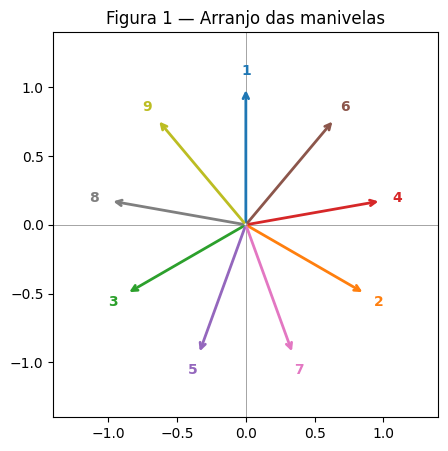

In [75]:
arranjo, _ = montar_esforcos(dados, alpha_g, F=1.0, a=a, harmonico=1)
plot_diagrama_vetorial(arranjo, 'Figura 1 — Arranjo das manivelas', mostrar_resultante=False)
plt.show()

### Esforços primários (forças e momentos de inércia)

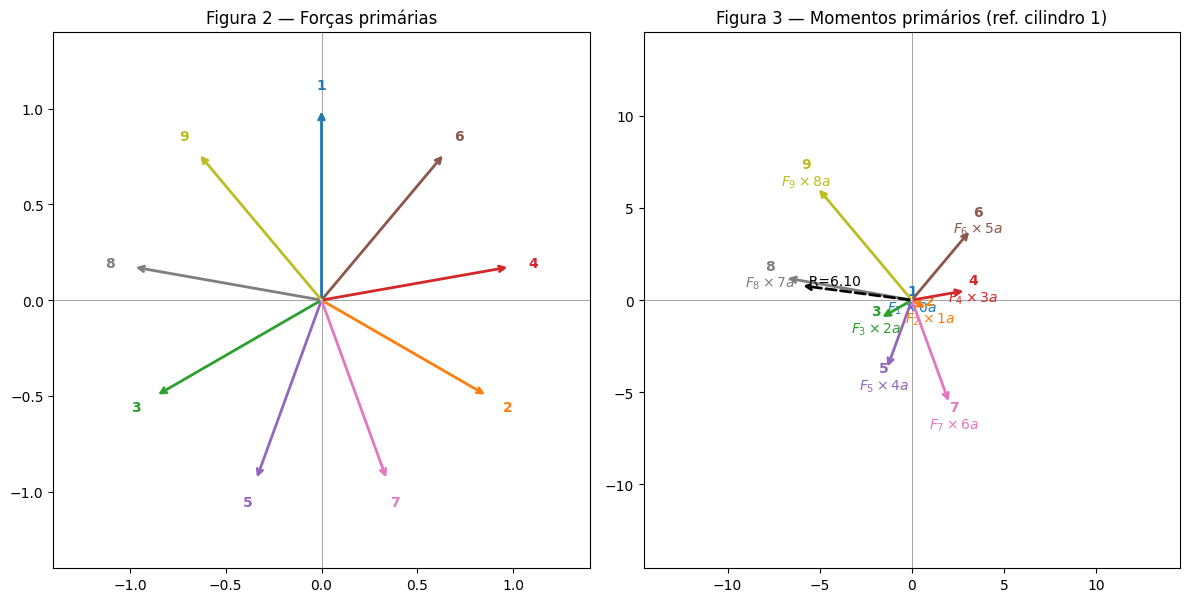

Resultante das forças primárias:  |R| = 0.000*F  -> BALANCEADO
Resultante dos momentos primários: |R| = 6.102*F*a -> DESBALANCEADO


In [76]:
forcas1, momentos1 = montar_esforcos(dados, alpha_g, F=F, a=a, harmonico=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
plot_diagrama_vetorial(forcas1, 'Figura 2 — Forças primárias', ax=axes[0])
plot_diagrama_vetorial(momentos1, 'Figura 3 — Momentos primários (ref. cilindro 1)',
                       ax=axes[1], mostrar_formula=True)
plt.tight_layout()
plt.show()

_, _, mr_f1 = resultante(forcas1)
_, _, mr_m1 = resultante(momentos1)
print(f"Resultante das forças primárias:  |R| = {mr_f1:.3f}*F  -> "
      f"{'BALANCEADO' if np.isclose(mr_f1, 0, atol=1e-6) else 'DESBALANCEADO'}")
print(f"Resultante dos momentos primários: |R| = {mr_m1:.3f}*F*a -> "
      f"{'BALANCEADO' if np.isclose(mr_m1, 0, atol=1e-6) else 'DESBALANCEADO'}")

### Esforços secundários (2º harmônico)

Mesma construção, usando `angulo_2 = 2*angulo_1`

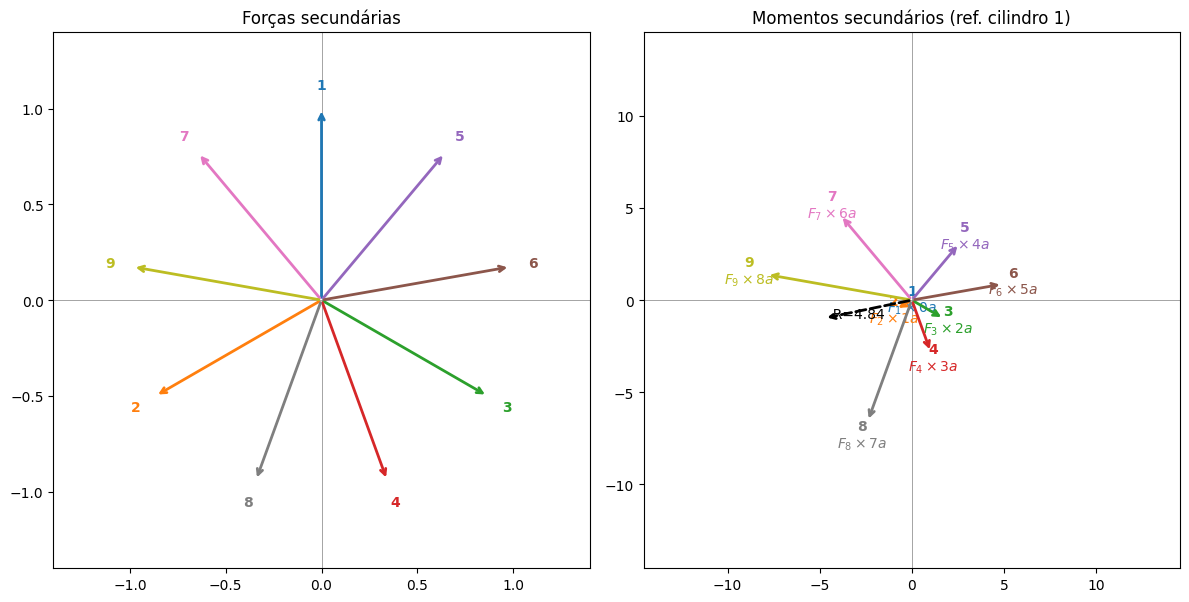

Resultante das forças secundárias:  |R| = 0.000*F  -> BALANCEADO
Resultante dos momentos secundários: |R| = 4.842*F*a -> DESBALANCEADO


In [77]:
forcas2, momentos2 = montar_esforcos(dados, alpha_g, F=F, a=a, harmonico=2)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
plot_diagrama_vetorial(forcas2, 'Forças secundárias', ax=axes[0])
plot_diagrama_vetorial(momentos2, 'Momentos secundários (ref. cilindro 1)',
                       ax=axes[1], mostrar_formula=True)
plt.tight_layout()
plt.show()

_, _, mr_f2 = resultante(forcas2)
_, _, mr_m2 = resultante(momentos2)
print(f"Resultante das forças secundárias:  |R| = {mr_f2:.3f}*F  -> "
      f"{'BALANCEADO' if np.isclose(mr_f2, 0, atol=1e-6) else 'DESBALANCEADO'}")
print(f"Resultante dos momentos secundários: |R| = {mr_m2:.3f}*F*a -> "
      f"{'BALANCEADO' if np.isclose(mr_m2, 0, atol=1e-6) else 'DESBALANCEADO'}")

### Esforços terciários (3º harmônico)

Mesma construção, usando `angulo_3 = 3*angulo_1`

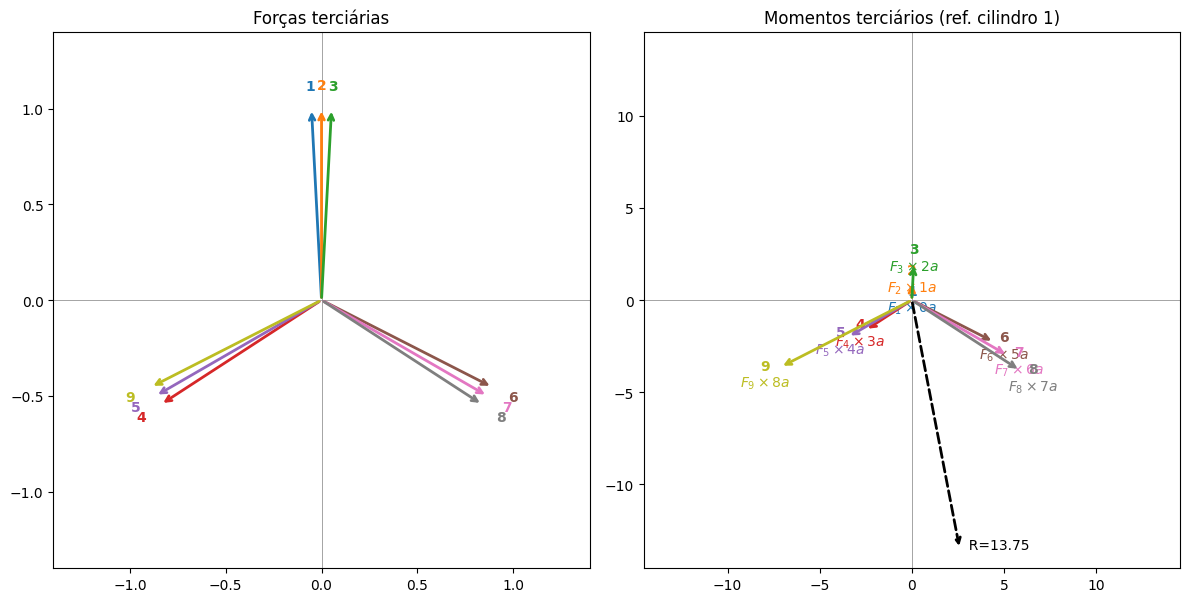

Resultante das forças terciárias:  |R| = 0.000*F  -> BALANCEADO
Resultante dos momentos terciários: |R| = 13.748*F*a -> DESBALANCEADO


In [78]:
forcas3, momentos3 = montar_esforcos(dados, alpha_g, F=F, a=a, harmonico=3)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
plot_diagrama_vetorial(forcas3, 'Forças terciárias', ax=axes[0])
plot_diagrama_vetorial(momentos3, 'Momentos terciários (ref. cilindro 1)',
                       ax=axes[1], mostrar_formula=True)
plt.tight_layout()
plt.show()

_, _, mr_f3 = resultante(forcas3)
_, _, mr_m3 = resultante(momentos3)
print(f"Resultante das forças terciárias:  |R| = {mr_f3:.3f}*F  -> "
      f"{'BALANCEADO' if np.isclose(mr_f3, 0, atol=1e-6) else 'DESBALANCEADO'}")
print(f"Resultante dos momentos terciários: |R| = {mr_m3:.3f}*F*a -> "
      f"{'BALANCEADO' if np.isclose(mr_m3, 0, atol=1e-6) else 'DESBALANCEADO'}")